# Data-Driven Analytics / Consulting Capstone Project
**Superstore Sales: why is profit unstable even when sales grow? (2014-2017)**

## Stage 1: Problem Definition

**Business problem:** The company's profit from 2014-2017 looks unstable. Management does not understand why profit is under pressure even though sales are increasing. Which Category, Region or Product is causing losses?

**Objectives**
1. Find the reason for the profit problem
2. Identify loss-making products and categories
3. Provide 3 actionable recommendations to management

**Data:** Superstore Sales dataset from Kaggle, period 2014 to 2017 (9,994 order lines, 21 columns).

## Stage 2: Data Cleaning
Import libraries, load the raw Excel file, check quality and fix the date columns.

In [4]:
# Import pandas: main library for reading Excel and working with tables (DataFrame)
import pandas as pd

In [5]:
# Import numpy: used later for conditional logic (np.where) and numeric work
import numpy as np

In [6]:
# Load the Superstore Excel file into a DataFrame called df (sheet name given explicitly)
# Keep the Excel file inside the repo's data/ folder so the relative path works on any computer
DATA_PATH = "../data/Superstore_Sales_data.xlsx"
df = pd.read_excel(DATA_PATH, sheet_name="Superstore Sales data")

In [7]:
# Check dataset size: (rows, columns) -> 9994 rows, 21 columns
print("Shape:",df.shape)

Shape: (9994, 21)


In [8]:
# Preview first 3 rows to understand the structure and spot problems (dates look odd here)
print(df.head(3))

   Row ID        Order ID           Order Date            Ship Date  \
0       1  CA-2016-152156  2016-08-11 00:00:00  2016-11-11 00:00:00   
1       2  CA-2016-152156  2016-08-11 00:00:00  2016-11-11 00:00:00   
2       3  CA-2016-138688  2016-12-06 00:00:00            6/16/2016   

      Ship Mode Customer ID    Customer Name    Segment        Country  \
0  Second Class    CG-12520      Claire Gute   Consumer  United States   
1  Second Class    CG-12520      Claire Gute   Consumer  United States   
2  Second Class    DV-13045  Darrin Van Huff  Corporate  United States   

          City  ... Postal Code  Region       Product ID         Category  \
0    Henderson  ...       42420   South  FUR-BO-10001798        Furniture   
1    Henderson  ...       42420   South  FUR-CH-10000454        Furniture   
2  Los Angeles  ...       90036    West  OFF-LA-10000240  Office Supplies   

  Sub-Category                                       Product Name   Sales  \
0    Bookcases                  

In [9]:
# Check data type of every column (Order Date / Ship Date are 'object', not datetime -> needs fixing)
print(df.dtypes)

Row ID             int64
Order ID             str
Order Date        object
Ship Date         object
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object


In [10]:
# Count missing values per column -> all 0, so no imputation needed
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [11]:
# Count fully duplicated rows -> 0, so no rows need to be removed
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [12]:
# Look closely at the two date columns: formats are mixed (timestamp vs text like 6/16/2016)
print(df[['Order Date','Ship Date']].head(3))

            Order Date            Ship Date
0  2016-08-11 00:00:00  2016-11-11 00:00:00
1  2016-08-11 00:00:00  2016-11-11 00:00:00
2  2016-12-06 00:00:00            6/16/2016


**The date problem**

- In Excel the value is `11-08-2016`, which means Nov 08, 2016 (MM-DD-YYYY).
- In Jupyter it reads `2016-08-11 00:00:00`, which means Aug 11, 2016.
- So pandas read `11-08-2016` as DD-MM-YYYY (11 = day, 08 = month) for some cells, and left other cells as plain text.

The `fix_date` function below repairs both cases.

In [14]:
# Custom function to fix the dates
# Why needed: some dates were read by pandas as real dates with day and month swapped,
# and others stayed as text in MM/DD/YYYY format. This function converts both into correct dates.
from datetime import datetime      # used for the isinstance() check below


def fix_date(x):
    if pd.isna(x):                  # blank cell -> return NaT (missing date)
        return pd.NaT
    if isinstance(x, (pd.Timestamp, datetime)):
        # Case 1: already parsed as a real date but day and month are swapped -> swap them back
        return pd.Timestamp(year=x.year, month=x.day, day=x.month)
    # Case 2: text date in month-first format
    x = str(x).strip()                         # remove extra spaces
    for fmt in ("%m/%d/%Y", "%m-%d-%Y"):       # try both separators, month first
        try:
            return pd.to_datetime(x, format=fmt)
        except ValueError:                     # format did not match -> try the next one
            pass
    return pd.NaT                              # nothing matched -> missing date

# Apply the fix to every value of both date columns
df["Order Date"] = df["Order Date"].apply(fix_date)
df["Ship Date"] = df["Ship Date"].apply(fix_date)

In [15]:
# Verify the fix: Ship Date should now be a few days AFTER Order Date
print(df[['Order Date','Ship Date']].head(3))

  Order Date  Ship Date
0 2016-11-08 2016-11-11
1 2016-11-08 2016-11-11
2 2016-06-12 2016-06-16


In [16]:
# Confirm both date columns are now datetime64 type
print(df.dtypes)

Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code               int64
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object


In [17]:
# Orders (rows) per year -> sanity check that all dates fall between 2014 and 2017
print(df['Order Date'].dt.year.value_counts())

Order Date
2017    3312
2016    2587
2015    2102
2014    1993
Name: count, dtype: int64


In [18]:
# First sort full data from 2014 onwards
df = df.sort_values(by='Order Date', ascending=True)   # oldest order first
df = df.reset_index(drop=True)                         # rebuild index 0,1,2... after sorting

# Now create new Row ID as 1,2,3
# NOTE: this overwrites the original Row ID; keep the old one in another column if you need traceability
df['Row ID'] = range(1, len(df) + 1)

print(df[['Row ID', 'Order Date']].head(10))          # check sorting and new IDs

   Row ID Order Date
0       1 2014-01-03
1       2 2014-01-04
2       3 2014-01-04
3       4 2014-01-04
4       5 2014-01-05
5       6 2014-01-06
6       7 2014-01-06
7       8 2014-01-06
8       9 2014-01-06
9      10 2014-01-06


In [19]:
# List all column names (useful for copying exact names, including spaces and hyphens)
print(df.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [20]:
# View first 5 rows of the cleaned and sorted data
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2014-103800,2014-01-03,2014-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,CA-2014-112326,2014-01-04,2014-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
2,3,CA-2014-112326,2014-01-04,2014-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
3,4,CA-2014-112326,2014-01-04,2014-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
4,5,CA-2014-141817,2014-01-05,2014-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [21]:
# Summary statistics of numeric/date columns (min, max, mean, quartiles) to spot outliers
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355,2016-05-03 23:06:58.571142,55190.379428,229.858001,3.789574,0.156203,28.656896
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108


In [22]:
# Total Sales for each year (group by the year part of Order Date)
df.groupby(df['Order Date'].dt.year)['Sales'].sum()

Order Date
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64

In [23]:
# Create New Columns
# Year number of the order (2014-2017), used for yearly grouping
df['Year'] = df['Order Date'].dt.year

In [24]:
# Month number of the order (1-12), useful for seasonality
df['Month'] = df['Order Date'].dt.month

In [25]:
# Year-Month label like '2016-11' (as text) for the monthly trend line
df['Year-Month'] = df['Order Date'].dt.to_period('M').astype(str)

In [26]:
# Profit margin per row = Profit / Sales (negative value means that line lost money)
df['Profit_Margin'] = df['Profit'] / df['Sales']

In [27]:
# Delivery time in days = Ship Date - Order Date
df['Delivery_Days'] = (df['Ship Date'] - df['Order Date']).dt.days

In [28]:
# Loss flag: label each row 'Loss' if Profit < 0, else 'Profit'
df['Profit_Status'] = np.where(df['Profit'] < 0, 'Loss', 'Profit')

In [32]:
# Check the new columns on the first 5 rows
df[['Year', 'Month', 'Profit_Margin', 'Delivery_Days', 'Profit_Status']].head()

,Year,Month,Profit_Margin,Delivery_Days,Profit_Status
0,2014,1,0.3375,4,Profit
1,2014,1,0.3625,4,Profit
2,2014,1,-0.2375,4,Loss
3,2014,1,-1.5500,4,Loss
4,2014,1,0.2500,7,Profit


In [33]:
# How many orders are in Loss?
# Expected: 1871 Loss rows vs 8123 Profit rows (about 18.7% of lines are loss-making)
df['Profit_Status'].value_counts()

Profit_Status
Profit    8123
Loss      1871
Name: count, dtype: int64

In [34]:
# What is the average Delivery Days?     (about 3.96 days)
df['Delivery_Days'].mean()

np.float64(3.958174904942966)

In [35]:
# Check the last 5 rows to make sure the derived columns are correct at the end of the data too
df[['Year', 'Month', 'Profit_Margin', 'Delivery_Days', 'Profit_Status']].tail()

,Year,Month,Profit_Margin,Delivery_Days,Profit_Status
9989,2017,12,-0.2000,4,Loss
9990,2017,12,0.3750,4,Profit
9991,2017,12,0.0300,4,Profit
9992,2017,12,0.3250,4,Profit
9993,2017,12,0.0375,4,Profit


In [39]:
# Same flag again (re-creates the same column, safe to re-run)
df['Profit_Status'] = np.where(df['Profit'] < 0, 'Loss', 'Profit')

In [40]:
# Confirm the label shows 'Profit' / 'Loss'
df[['Year', 'Month', 'Profit_Margin', 'Delivery_Days', 'Profit_Status']].head()

,Year,Month,Profit_Margin,Delivery_Days,Profit_Status
0,2014,1,0.3375,4,Profit
1,2014,1,0.3625,4,Profit
2,2014,1,-0.2375,4,Loss
3,2014,1,-1.5500,4,Loss
4,2014,1,0.2500,7,Profit


<Axes: xlabel='Year-Month'>

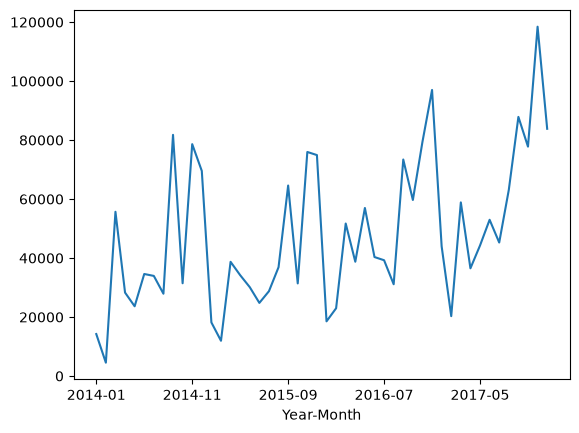

In [41]:
# Month wise sales trend
# Sum sales per Year-Month and draw a line chart (shows growth and seasonal peaks around Nov-Dec)
# TIP: add a title, axis labels and rotate x-axis labels to make the chart presentation-ready
df.groupby('Year-Month')['Sales'].sum().plot()

In [ ]:
# Year wise profit margin
# Weighted margin = total Profit / total Sales for each year (the correct measure for management reporting)
yearly = df.groupby('Year')[['Sales','Profit']].sum()
yearly['Profit_Margin_%'] = yearly['Profit'] / yearly['Sales'] * 100
yearly

            Sales      Profit  Profit_Margin_%
Year                                          
2014  484247.4981  49543.9741        10.231126
2015  470532.5090  61618.6037        13.095504
2016  609205.5980  81795.1743        13.426530
2017  733215.2552  93439.2696        12.743771

In [45]:
# 1. Do Loss orders take different delivery time?
# Result: Loss 3.97 vs Profit 3.95 days -> almost no difference, so delivery time is not a cause of loss
df.groupby('Profit_Status')['Delivery_Days'].mean()


Profit_Status
Loss      3.972207
Profit    3.954943
Name: Delivery_Days, dtype: float64

In [46]:
# 2. Which Ship Mode gives less profit?
# Average delivery days, margin and discount for each shipping mode
# Result: Standard Class has the lowest average margin (about 11%)
df.groupby('Ship Mode')[['Delivery_Days','Profit_Margin','Discount']].mean()


,Delivery_Days,Profit_Margin,Discount
Ship Mode,,,
First Class,2.182705,0.115948,0.164610
Same Day,0.044199,0.138151,0.152394
Second Class,3.238046,0.150209,0.138895
Standard Class,5.006535,0.110073,0.160023


In [49]:
# 3. What is the correlation?
# Result: Discount vs Profit_Margin = -0.86 (strong negative) -> higher discount, lower margin.
#         Delivery_Days has almost zero correlation with margin or discount.
df[['Delivery_Days','Profit_Margin','Discount']].corr()

,Delivery_Days,Profit_Margin,Discount
Delivery_Days,1.000000,-0.011815,0.000408
Profit_Margin,-0.011815,1.000000,-0.864452
Discount,0.000408,-0.864452,1.000000


In [50]:
# Save Clean CSV ( This will go to SQL)
# index=False so the pandas index is not written as an extra column
df.to_csv("Clean_Superstore.csv", index=False)

In [51]:
# Confirmation message that the file was saved
print("Cleaned data saved")

Cleaned data saved


In [52]:
# Final look at the cleaned data before starting EDA
print(df.head())

   Row ID        Order ID Order Date  Ship Date       Ship Mode Customer ID  \
0       1  CA-2014-103800 2014-01-03 2014-01-07  Standard Class    DP-13000   
1       2  CA-2014-112326 2014-01-04 2014-01-08  Standard Class    PO-19195   
2       3  CA-2014-112326 2014-01-04 2014-01-08  Standard Class    PO-19195   
3       4  CA-2014-112326 2014-01-04 2014-01-08  Standard Class    PO-19195   
4       5  CA-2014-141817 2014-01-05 2014-01-12  Standard Class    MB-18085   

   Customer Name      Segment        Country          City  ...    Sales  \
0  Darren Powers     Consumer  United States       Houston  ...   16.448   
1  Phillina Ober  Home Office  United States    Naperville  ...   11.784   
2  Phillina Ober  Home Office  United States    Naperville  ...  272.736   
3  Phillina Ober  Home Office  United States    Naperville  ...    3.540   
4     Mick Brown     Consumer  United States  Philadelphia  ...   19.536   

   Quantity Discount   Profit  Year Month Year-Month  Profit_Margin 

## Stage 3: Exploratory Data Analysis (EDA)
Find the patterns in the data: category, region, state, sub-category, product and segment.

In [54]:
# Q2: Category wise Sales vs Profit
# Result: Furniture earns very little profit (about 18K on 742K sales) vs Technology (145K) and Office Supplies (122K)
print(df.groupby('Category')[['Sales','Profit']].sum())

                       Sales       Profit
Category                                 
Furniture        741999.7953   18451.2728
Office Supplies  719047.0320  122490.8008
Technology       836154.0330  145454.9481


In [55]:
# Q3: Region wise Net Profit
# Net profit per region (West and East are strongest, Central is weakest)
print(df.groupby('Region')['Profit'].sum())

Region
Central     39706.3625
East        91522.7800
South       46749.4303
West       108418.4489
Name: Profit, dtype: float64


In [56]:
# Q3: Region wise Loss
# Only rows with negative profit, summed per region -> Central has the biggest losses
print(df[df['Profit']<0].groupby('Region')['Profit'].sum())

Region
Central   -56314.8850
East      -49590.6075
South     -27504.8323
West      -22720.9609
Name: Profit, dtype: float64


In [57]:
# Q4: Year wise trend
# Sales and Profit per year -> both grow from 2014 to 2017 (total profit is NOT falling in this data)
print(df.groupby('Year')[['Sales','Profit']].sum())


            Sales      Profit
Year                         
2014  484247.4981  49543.9741
2015  470532.5090  61618.6037
2016  609205.5980  81795.1743
2017  733215.2552  93439.2696


In [58]:
# Q5: Discount vs Profit
# Average discount and average profit per sub-category, sorted from worst to best profit.
# Result: Tables, Bookcases and Supplies lose money on average; Tables/Bookcases also carry high discounts.
# NOTE: Binders (37%) and Machines (31%) have the highest discounts, so they are the next at-risk sub-categories.
print(df.groupby('Sub-Category')[['Discount','Profit']].mean().sort_values(by='Profit'))


              Discount      Profit
Sub-Category                      
Tables        0.261285  -55.565771
Bookcases     0.211140  -15.230509
Supplies      0.076842   -6.258418
Fasteners     0.082028    4.375660
Art           0.074874    8.200737
Furnishings   0.138349   13.645918
Labels        0.068681   15.236962
Binders       0.372292   19.843574
Paper         0.074891   24.856620
Storage       0.074704   25.152277
Envelopes     0.080315   27.418019
Machines      0.306087   29.432669
Appliances    0.166524   38.922758
Chairs        0.170178   43.095894
Phones        0.154556   50.073938
Accessories   0.078452   54.111788
Copiers       0.161765  817.909190


In [59]:
# Q6: Top 10 Profitable Products
# Total profit per product, sorted high to low, top 10 shown (copiers and binding machines lead)
print(df.groupby('Product Name')['Profit'].sum().sort_values(ascending=False).head(10))

Product Name
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Canon PC1060 Personal Laser Copier                                              4570.9347
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Ativa V4110MDD Micro-Cut Shredder                                               3772.9461
3D Systems Cube Printer, 2nd Generation, Magenta                                3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System                      3696.2820
Ibico EPK-21 Electric Binding System                                            3345.2823
Zebra ZM400 Thermal Label Printer                                               3343.5360
Name: Profit, dtype: float64


In [60]:
# Q6B: Top 10 Loss Products
# Same calculation, sorted low to high -> the 10 biggest loss-making products (3D printers and conference tables)
print(df.groupby('Product Name')['Profit'].sum().sort_values().head(10))

Product Name
Cubify CubeX 3D Printer Double Head Print                           -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                           -4589.9730
Cubify CubeX 3D Printer Triple Head Print                           -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases            -2876.1156
Bush Advantage Collection Racetrack Conference Table                -1934.3976
GBC DocuBind P400 Electric Binding System                           -1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit               -1811.0784
Martin Yale Chadless Opener Electric Letter Opener                  -1299.1836
Balt Solid Wood Round Tables                                        -1201.0581
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables   -1148.4375
Name: Profit, dtype: float64


In [61]:
# Q7: Segment wise
# Sales and profit by customer segment (Consumer, Corporate, Home Office)
print(df.groupby('Segment')[['Sales','Profit']].sum())

                    Sales       Profit
Segment                               
Consumer     1.161401e+06  134119.2092
Corporate    7.061464e+05   91979.1340
Home Office  4.296531e+05   60298.6785


In [62]:
# Q3B: State wise Loss (Most important)
# 10 states with the lowest total profit (Texas, Ohio, Pennsylvania, Illinois are the worst)
print(df.groupby('State')['Profit'].sum().sort_values().head(10))

State
Texas            -25729.3563
Ohio             -16971.3766
Pennsylvania     -15559.9603
Illinois         -12607.8870
North Carolina    -7490.9122
Colorado          -6527.8579
Tennessee         -5341.6936
Arizona           -3427.9246
Florida           -3399.3017
Oregon            -1190.4705
Name: Profit, dtype: float64


In [63]:
# Install libraries needed to talk to SQL Server (already installed here, so this only confirms it)
# sqlalchemy = Python-to-database toolkit, pyodbc = ODBC driver connector
# TIP: keep installs in a separate setup step, not in the final analysis notebook
!pip install sqlalchemy pyodbc

In [64]:
# Import sqlalchemy to build a database connection
import sqlalchemy

In [65]:
# 1. Create connection to SQL
# Connects to local SQL Server Express, database 'SuperstoreDB', using Windows login (trusted_connection=yes)
engine = sqlalchemy.create_engine(
    r'mssql+pyodbc://localhost\SQLEXPRESS/SuperstoreDB?driver=ODBC Driver 17 for SQL Server&trusted_connection=yes'
)

In [66]:
# 2. Load the clean data (df) into SQL Server
# Creates table 'CleanedOrders'; if_exists='replace' DROPS and recreates it if it already exists
# NOTE: column names like 'Sub-Category' and 'Year-Month' need [square brackets] in SQL queries
df.to_sql('CleanedOrders', con=engine, if_exists='replace', index=False)

print("Done! Data moved to SQL")

Done! Data moved to SQL


In [67]:
# Discount bucket analysis: does a higher discount mean lower profit?
# Group the Discount values into 4 buckets (0%, 1-20%, 21-40%, above 40%)
bins = [-0.001, 0, 0.2, 0.4, 1]
labels = ['0%', '1-20%', '21-40%', '40%+']
df['Discount_Bucket'] = pd.cut(df['Discount'], bins=bins, labels=labels)

# For each bucket: number of rows, total sales, total profit and number of loss-making rows
summary = df.groupby('Discount_Bucket', observed=True).agg(
    Orders=('Order ID', 'count'),
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Loss_Rows=('Profit', lambda s: (s < 0).sum())
)

# Weighted margin (total profit / total sales) and share of loss-making rows in each bucket
summary['Margin_%'] = summary['Profit'] / summary['Sales'] * 100
summary['Loss_Rows_%'] = summary['Loss_Rows'] / summary['Orders'] * 100
summary.round(2)

,Orders,Sales,Profit,Loss_Rows,Margin_%,Loss_Rows_%
Discount_Bucket,,,,,,
0%,4798,1087908.47,320987.60,0,29.51,0.00
1-20%,3803,846522.24,100785.47,523,11.91,13.75
21-40%,460,234137.90,-35817.47,415,-15.30,90.22
40%+,933,128632.25,-99558.59,933,-77.40,100.00


**Reading the table:** Margin falls and the share of loss-making rows rises as the discount bucket increases.
At 0% discount the margin is 29.5% and no row loses money; at 40%+ discount the margin is -77.4% and every row (933 of 933) loses money.
This is the evidence that discounting is the main driver of loss.

## Stage 4: Key Findings and Recommendations

**Data check:** 9,994 rows, no nulls, no duplicates. Totals after cleaning match the raw file: Sales 2,297,200.86 and Profit 286,397.02. Delivery days range from 0 to 7 (no negative values), which confirms the date fix.

**Headline:** Total profit did not fall. It rose every year (49.5K, 61.6K, 81.8K, 93.4K) with sales (484K, 471K, 609K, 733K). The real problem is margin quality: overall margin is only 12.5%, 18.7% of order lines (1,871 of 9,994) lose money, and the 2017 margin (12.7%) slipped below 2016 (13.4%).

| Discount | Rows | Sales | Profit | Margin | Loss rows |
|---|---|---|---|---|---|
| 0% | 4,798 | 1,087,908 | 320,988 | 29.5% | 0% |
| 1-20% | 3,803 | 846,522 | 100,785 | 11.9% | 13.8% |
| 21-40% | 460 | 234,138 | -35,817 | -15.3% | 90.2% |
| 40%+ | 933 | 128,632 | -99,559 | -77.4% | 100% |

**Root cause: discounting.** Discount vs Profit_Margin correlation is -0.86. Rows with more than 20% discount are 13.9% of rows (15.8% of sales) but lose 135K combined. Delivery time and ship mode are not the cause (loss vs profit delivery days: 3.97 vs 3.95).

**Where losses sit:** Furniture margin 2.5% (Technology 17.4%, Office Supplies 17.0%); Tables, Bookcases and Supplies lose money overall; Central region (lowest profit 39.7K, average discount 24% vs 11% in West); Texas, Ohio, Pennsylvania, Illinois (average discount 33-39%); Cubify CubeX 3D printers and Lexmark MX611dhe printer are the worst products.

**Recommendations**
1. Cap discounts at 20% and require management approval above it. Start with Tables, Bookcases, Binders and Machines.
2. Reprice or drop the worst loss-making products (Cubify CubeX 3D printers, Lexmark MX611dhe, loss-making conference tables).
3. Review discount and cost policy in the Central region and the loss-making states, and push growth in high-margin Technology and Office Supplies.